# [Lab Session 2](otsu.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [3]:
imgf = plt.imread('data/NIH3T3/im/dna-0.png')

**[Task 1.2.]()** Quantify the image into 256 bins:

In [4]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [5]:
h = np.zeros(256)

for i in range(256):
    h[i] = np.sum(img8 == i)

Show the computed histogram:

In [6]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

<BarContainer object of 256 artists>

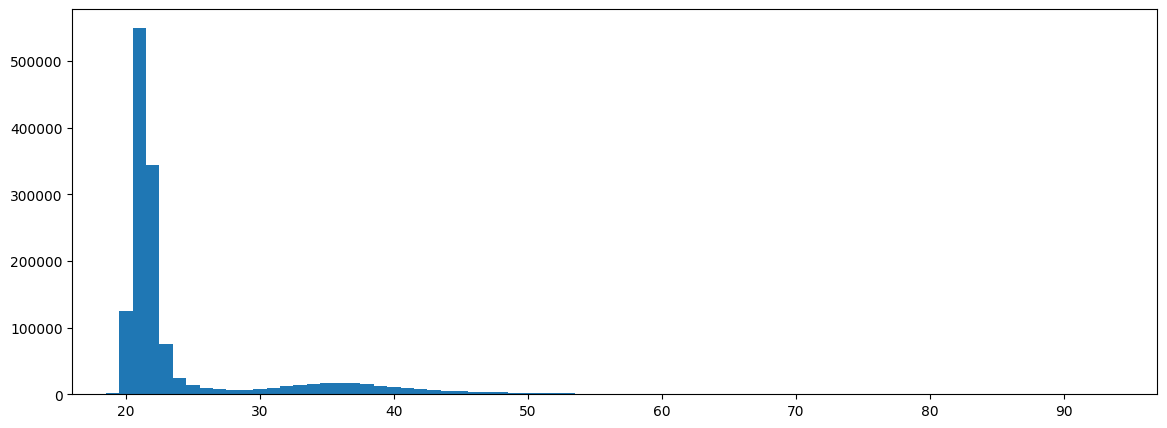

In [8]:
nz = np.nonzero(h)[0]          # intensities that actually occur
plt.figure(figsize=(14, 5))
plt.bar(range(256), h, width=1)
plt.xlim(nz.min() - 2, nz.max() + 2)
plt.show()

**[Task 1.4.]()** Implement the method of Otsu:

In [21]:
sum_wcv = np.zeros(256)

for T in range (256):
    sum_wcv[T] = (np.sum(h[:T])*np.var(img8[img8 < T]) + (np.sum(h[T:])*np.var(img8[img8 >=T])))

sum_wcv

/usr/local/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3787: RuntimeWarning: Degrees of freedom <= 0 for slice
  return _methods._var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.12/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/usr/local/lib/python3.12/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


array([              nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan,               nan,               nan,
                     nan, 62268423.49896929, 62231302.67756923,
       59818223.62454262, 47165648.8532488 , 27449150.57824366,
       18586354.36935248, 15253989.89752736, 13539656.28011815,
       12557445.78895864, 11933561.89796724, 11536254.18924297,
       11313729.00229155, 11275653.93934225, 11495860.3303481 ,
       12094366.78891711, 13176916.55272644, 14767374.26909976,
       16902177.86318459, 19466392.13648611, 22316940.04301708,
       25216024.01878978, 28108330.89532448, 30810951.55526169,
       33287950.23202944, 35560795.16565558, 37671210.81379128,
       39656813.25915194, 41533993.49633

In [22]:
T_best = np.nanargmin(sum_wcv)
print(T_best)
print(sum_wcv[T_best])


31
11275653.93934225


**[Task 1.5.]()** Perform Otsu thresholding:

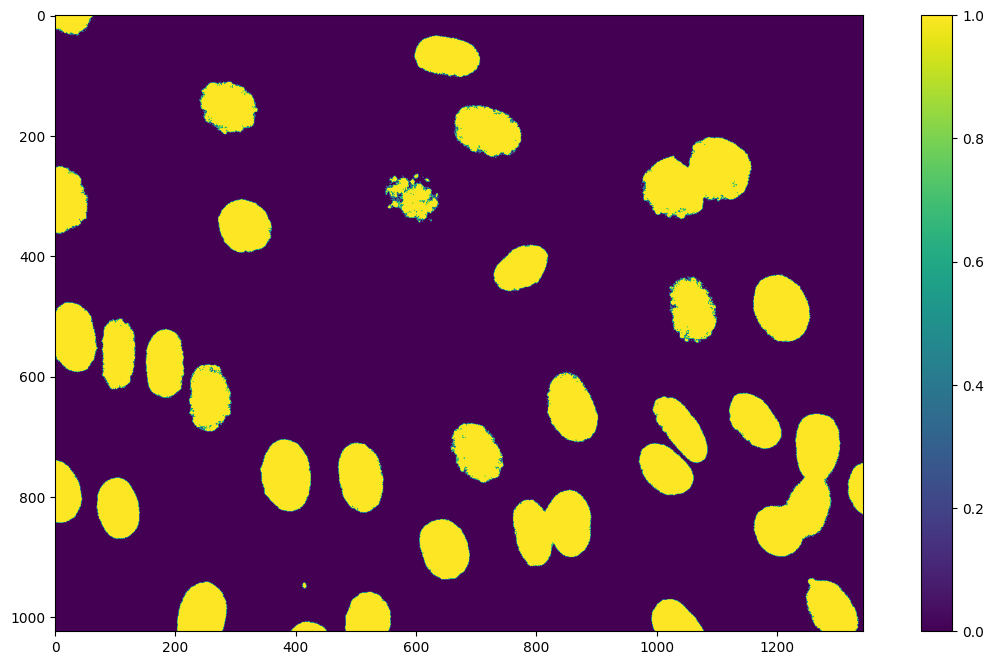

In [28]:
img_2 = img8.copy()

T=31

for x in range(1024):
    for y in range(1344):
        if img_2[x,y] >= T:
            img_2[x,y] = 1
        else :
            img_2[x,y] = 0 


plt.figure(figsize=(15,8))
plt.imshow(img_2)
plt.colorbar()

**[Task 1.6.]()** Compute the Dice coefficient:

In [29]:
gt = plt.imread('data/NIH3T3/gt/0.png').astype(bool)

def compute_dice(G, H):
    #assert G.dtype == bool and H.dtype == bool
    return 2 * (G * H).sum() / (G.sum() + H.sum())

dice = compute_dice(img_2, gt )
print(dice)

0.8943783223933183
